# 04 - Embeat Recommendation Model Evaluation

## 1. Mục tiêu
Đánh giá năm phương pháp đề xuất trên cùng tập truy vấn:
1. Audio-only
2. Hybrid 70/30
3. Hybrid + MMR
4. Random Baseline
5. Popularity Baseline

## 2. Chỉ số
- Mean Audio Cosine: tương đồng âm học trung bình (cao hơn nghĩa là gần hơn về âm học)
- Mean Acoustic Distance: 1 - cosine (thấp hơn nghĩa là gần hơn về âm học)
- Audio Diversity: 1 - mean pairwise audio cosine trong danh sách gợi ý
- Coverage (%): tỷ lệ bài hát khác nhau được đề xuất trên tổng catalog
- Mean Latency (ms): thời gian phản hồi trung bình

## 3. Cấu hình
- Dataset/model artifact: lấy theo artifact hiện tại trong `artifacts/`
- Queries: 30; Top-N: 10; Alpha: 0.7; MMR Lambda: 0.7
- Candidate Pool: mặc định động `3 * top_n` khi không truyền giá trị tường minh
- Random State: 42

Giới hạn: Không có nhãn relevance ground truth; không báo cáo Accuracy, Precision@K hoặc Recall@K. Độ tương đồng âm học không phải độ chính xác theo sở thích người dùng.


In [19]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [20]:
from pathlib import Path
import os
import sys
import json
import time
import inspect

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def _is_project_root(path):
    return (
        path.is_dir()
        and (path / "src" / "evaluate.py").is_file()
        and (path / "src" / "recommender.py").is_file()
    )

candidate_roots = []

# 1. Explicit environment variable is the most portable option.
configured_root = os.environ.get("EMBEAT_PROJECT_ROOT")
if configured_root:
    candidate_roots.append(Path(configured_root).expanduser())

# 2. Current working directory and its parents.
cwd = Path.cwd().resolve()
candidate_roots.extend([cwd, *cwd.parents])

# 3. If running in Colab with Drive mounted, discover the project directory
# by structure rather than embedding a project-specific absolute path.
drive_root = Path("/content/drive/MyDrive")
if drive_root.is_dir():
    candidate_roots.extend(
        child for child in drive_root.iterdir()
        if child.is_dir()
    )

PROJECT_ROOT = None
seen = set()
for candidate in candidate_roots:
    try:
        resolved = candidate.resolve()
    except OSError:
        continue
    if resolved in seen:
        continue
    seen.add(resolved)
    if _is_project_root(resolved):
        PROJECT_ROOT = resolved
        break

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Không tìm thấy project root. Đặt biến môi trường "
        "EMBEAT_PROJECT_ROOT hoặc mở notebook trong thư mục project."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import src.evaluate as evaluation

ARTIFACT_PATH = PROJECT_ROOT / "artifacts" / "embeat_recommender.joblib"
REPORTS_DIR = PROJECT_ROOT / "reports"
FIGURES_DIR = REPORTS_DIR / "figures"
METADATA_PATH = ARTIFACT_PATH.with_name(
    f"{ARTIFACT_PATH.stem}_metadata.json"
)

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

evaluation.ARTIFACT_PATH = ARTIFACT_PATH
evaluation.OUTPUT_DIR = REPORTS_DIR

EVALUATION_STARTED_AT = None

print("Project root:", PROJECT_ROOT)
print("Artifact:", ARTIFACT_PATH)
print("Reports directory:", REPORTS_DIR)
print("Dashboard directory:", FIGURES_DIR)
assert ARTIFACT_PATH.is_file(), "Main model artifact not found"
assert ARTIFACT_PATH.stat().st_size > 0, "Artifact is empty"
print("PROJECT DISCOVERY: PASS")


Project root: /content/drive/MyDrive/music_recommender_project
Artifact: /content/drive/MyDrive/music_recommender_project/artifacts/embeat_recommender.joblib
Reports directory: /content/drive/MyDrive/music_recommender_project/reports
Dashboard directory: /content/drive/MyDrive/music_recommender_project/reports/figures
PROJECT DISCOVERY: PASS


In [21]:
assert len(evaluation.MODEL_CONFIGS) == 5
print("PASS: All five evaluation modes are configured.")


PASS: All five evaluation modes are configured.


In [22]:
configs = evaluation.MODEL_CONFIGS

expected_modes = {"audio", "hybrid", "mmr", "random", "popularity"}
assert len(configs) == 5
assert {item["mode"] for item in configs} == expected_modes
assert len({item["name"] for item in configs}) == 5

print("Evaluation modes:")
for config in configs:
    print(config)

print("\\nPASS: All five evaluation modes are configured.")


Evaluation modes:
{'name': 'Audio-only', 'mode': 'audio'}
{'name': 'Hybrid 70/30', 'mode': 'hybrid'}
{'name': 'Hybrid + MMR', 'mode': 'mmr'}
{'name': 'Random Baseline', 'mode': 'random'}
{'name': 'Popularity Baseline', 'mode': 'popularity'}
\nPASS: All five evaluation modes are configured.


In [23]:
print("=== EVALUATION CONFIGURATION ===")
print("Top N:", evaluation.TOP_N)
print("Number of queries:", evaluation.N_QUERIES)
print("Alpha:", evaluation.ALPHA)
print("MMR Lambda:", evaluation.MMR_LAMBDA)
print("Random State:", evaluation.RANDOM_STATE)
print("Candidate pool policy: dynamic (3 * top_n when omitted)")
print("Artifact exists:", ARTIFACT_PATH.exists())
print("Artifact size (MB):", round(ARTIFACT_PATH.stat().st_size / (1024 ** 2), 2))
print("Reports directory exists:", REPORTS_DIR.exists())


=== EVALUATION CONFIGURATION ===
Top N: 10
Number of queries: 30
Alpha: 0.7
MMR Lambda: 0.7
Random State: 42
Candidate pool policy: dynamic (3 * top_n when omitted)
Artifact exists: True
Artifact size (MB): 6.62
Reports directory exists: True


In [24]:
# Chỉ chấp nhận reports được tạo/cập nhật bởi lần evaluation hiện tại.
EVALUATION_STARTED_AT = time.time()
evaluation.main()

print("EVALUATION MAIN: COMPLETED")


Loaded: 29985 tracks; audio: (29985, 9) ; genres: (29985, 4211)
Evaluating: Audio-only (mode=audio)
Evaluating: Hybrid 70/30 (mode=hybrid)
Evaluating: Hybrid + MMR (mode=mmr)
Evaluating: Random Baseline (mode=random)
Evaluating: Popularity Baseline (mode=popularity)
Dashboard saved: /content/drive/MyDrive/music_recommender_project/reports/figures/evaluation_dashboard.png
              model  mean_audio_cosine  mean_acoustic_distance  audio_diversity  coverage_pct  mean_latency_ms
         Audio-only           0.960541                0.039459         0.064865      1.000500        18.981033
       Hybrid 70/30           0.929475                0.070525         0.096500      1.000500        25.418041
       Hybrid + MMR           0.933300                0.066700         0.109735      1.000500        28.276398
    Random Baseline           0.013582                0.986418         0.986175      0.997165         7.444793
Popularity Baseline           0.027189                0.972811         

In [25]:
assert EVALUATION_STARTED_AT is not None, "Evaluation cell chưa chạy."
metrics_path = REPORTS_DIR / "metrics.json"
summary_path = REPORTS_DIR / "evaluation_summary.csv"
details_path = REPORTS_DIR / "evaluation_details.csv"
dashboard_path = FIGURES_DIR / "evaluation_dashboard.png"

for path in [metrics_path, summary_path, details_path, dashboard_path]:
    assert path.is_file(), f"Thiếu output: {path}"
    assert path.stat().st_mtime >= EVALUATION_STARTED_AT - 1, (
        f"{path.name} là output cũ, không thuộc lần evaluation hiện tại."
    )

with open(metrics_path, "r", encoding="utf-8") as file:
    metrics = json.load(file)

summary_df = pd.read_csv(summary_path)
details_df = pd.read_csv(details_path)

print("=== EVALUATION CONFIG ===")
print(json.dumps(metrics["evaluation_config"], indent=4, ensure_ascii=False))
print("\\n=== EVALUATION SUMMARY ===")
display(summary_df)
print("\\n=== EVALUATION DETAILS ===")
display(details_df.head(10))

print("\\nCURRENT-RUN REPORT FILES: PASS")


=== EVALUATION CONFIG ===
{
    "n_queries": 30,
    "top_n": 10,
    "alpha": 0.7,
    "mmr_lambda": 0.7,
    "candidate_pool": null,
    "candidate_pool_policy": "3 * top_n when not explicitly provided",
    "random_state": 42
}
\n=== EVALUATION SUMMARY ===


,model,mode,total_queries,total_recommendations,unique_recommended_tracks,avg_unique_artists,avg_unique_genres,avg_popularity,mean_latency_ms,median_latency_ms,...,mean_audio_cosine,mean_acoustic_distance,mean_hybrid_cosine,audio_diversity,hybrid_diversity,avg_similarity,intra_list_diversity,catalog_size,coverage_pct,avg_mmr_score
0,Audio-only,audio,30,300,300,9.7,12.400000,0.266100,18.981033,18.275256,...,0.960541,0.039459,0.682358,0.064865,0.337191,0.960541,0.064865,29985,1.000500,NaN
1,Hybrid 70/30,hybrid,30,300,300,9.0,11.200000,0.309800,25.418041,24.673149,...,0.929475,0.070525,0.720761,0.096500,0.303106,0.929475,0.096500,29985,1.000500,NaN
2,Hybrid + MMR,mmr,30,300,300,9.4,11.166667,0.259667,28.276398,28.200933,...,0.933300,0.066700,0.716811,0.109735,0.329693,0.933300,0.109735,29985,1.000500,0.311717
3,Random Baseline,random,30,300,299,10.0,14.133333,0.268433,7.444793,7.300139,...,0.013582,0.986418,0.011200,0.986175,0.989832,0.013582,0.986175,29985,0.997165,NaN
4,Popularity Baseline,popularity,30,300,10,10.0,30.000000,0.820000,17.265418,16.888355,...,0.027189,0.972811,0.021856,0.741555,0.812168,0.027189,0.741555,29985,0.033350,NaN


\n=== EVALUATION DETAILS ===


,model,query_id,rank,track_id,track_name,artist_name,artist_genres,popularity,mean_audio_cosine,mean_acoustic_distance,mean_hybrid_cosine,audio_diversity,hybrid_diversity,similarity,audio_similarity,genre_similarity,hybrid_similarity,mmr_score
0,Audio-only,20VBgkEWUKqnTa677QQPX0,1,3gky07d1PehSRTQ1GIRJBZ,JOY COMES FROM THE LORD,KS,NaN,0.02,0.87581,0.12419,0.613067,0.203169,0.442218,0.954833,NaN,NaN,NaN,NaN
1,Audio-only,20VBgkEWUKqnTa677QQPX0,2,20VUAbNMl2JaWD5Ti2LUAp,Bitte hört auf,JACE,"german alternative rap, german cloud rap",0.07,0.87581,0.12419,0.613067,0.203169,0.442218,0.946256,NaN,NaN,NaN,NaN
2,Audio-only,20VBgkEWUKqnTa677QQPX0,3,4aOOExMBUyxKnEYb39SrTg,Riot,XXXTENTACION,"miami hip hop, emo rap",0.73,0.87581,0.12419,0.613067,0.203169,0.442218,0.942706,NaN,NaN,NaN,NaN
3,Audio-only,20VBgkEWUKqnTa677QQPX0,4,3gbkvfmlNd4r8MaDyuwTIv,Control dis .40,Damnnnsolo,NaN,0.02,0.87581,0.12419,0.613067,0.203169,0.442218,0.942399,NaN,NaN,NaN,NaN
4,Audio-only,20VBgkEWUKqnTa677QQPX0,5,7eRJjg52FkSmQvmNQDYpMl,worst behaviour (feat. Kehlani),Kehlani,"r&b, pop, rap",0.76,0.87581,0.12419,0.613067,0.203169,0.442218,0.933901,NaN,NaN,NaN,NaN
5,Audio-only,20VBgkEWUKqnTa677QQPX0,6,3hLAKLijSDedibJSB1BwxT,bbo,lordkez,south african r&b,0.02,0.87581,0.12419,0.613067,0.203169,0.442218,0.933284,NaN,NaN,NaN,NaN
6,Audio-only,20VBgkEWUKqnTa677QQPX0,7,1yYg5wpCJybzFUeD0TUDlK,Solid Foundation,Illuminati Congo,"spiritual hip hop, high vibe",0.07,0.87581,0.12419,0.613067,0.203169,0.442218,0.932889,NaN,NaN,NaN,NaN
7,Audio-only,20VBgkEWUKqnTa677QQPX0,8,1Mzg6bu3hkCwJKEf7v49MN,CARTIER SANTOS,SDM,"pop urbaine, french hip hop, r&b francais",0.77,0.87581,0.12419,0.613067,0.203169,0.442218,0.932329,NaN,NaN,NaN,NaN
8,Audio-only,20VBgkEWUKqnTa677QQPX0,9,3h2fb1JsD4FK1FPkAJjwyW,Powiedz co czujesz,KD Producent,NaN,0.02,0.87581,0.12419,0.613067,0.203169,0.442218,0.930255,NaN,NaN,NaN,NaN
9,Audio-only,20VBgkEWUKqnTa677QQPX0,10,20WujVDIQfXZDy2g3pzIGM,Ezekiel 33,Streetlights,bible,0.07,0.87581,0.12419,0.613067,0.203169,0.442218,0.930197,NaN,NaN,NaN,NaN


\nCURRENT-RUN REPORT FILES: PASS


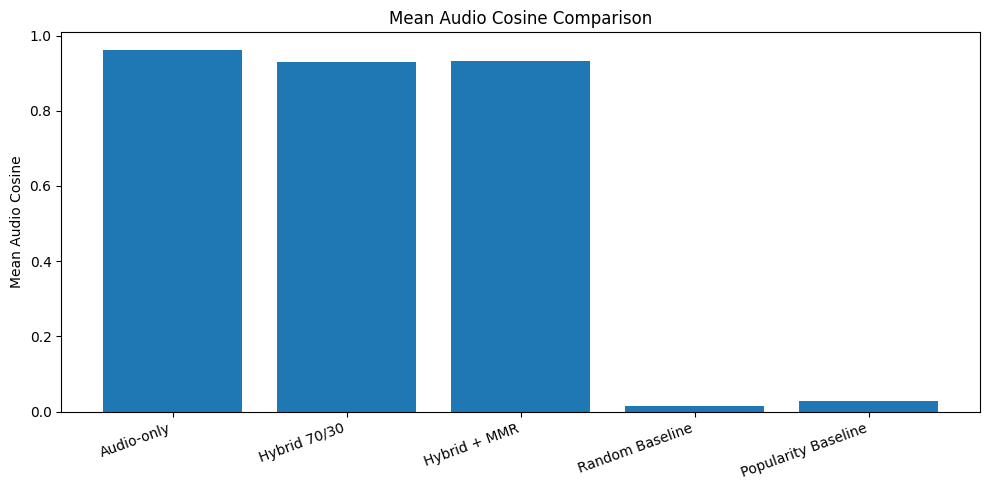

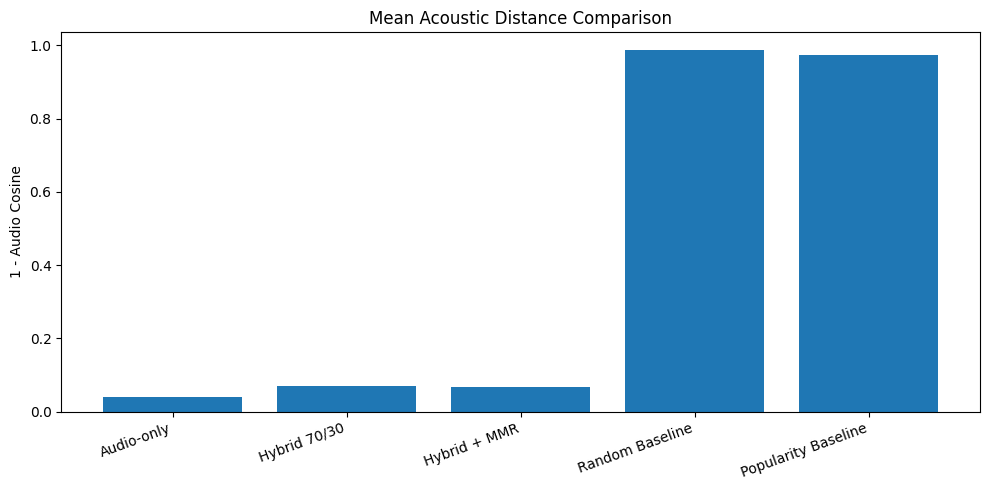

In [26]:
required_metrics = ["model", "mean_audio_cosine", "mean_acoustic_distance", "audio_diversity", "coverage_pct", "mean_latency_ms"]
missing = [col for col in required_metrics if col not in summary_df.columns]
assert not missing, f"Missing evaluation columns: {missing}. Check src/evaluate.py version."

plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["mean_audio_cosine"])
plt.title("Mean Audio Cosine Comparison")
plt.ylabel("Mean Audio Cosine")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["mean_acoustic_distance"])
plt.title("Mean Acoustic Distance Comparison")
plt.ylabel("1 - Audio Cosine")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


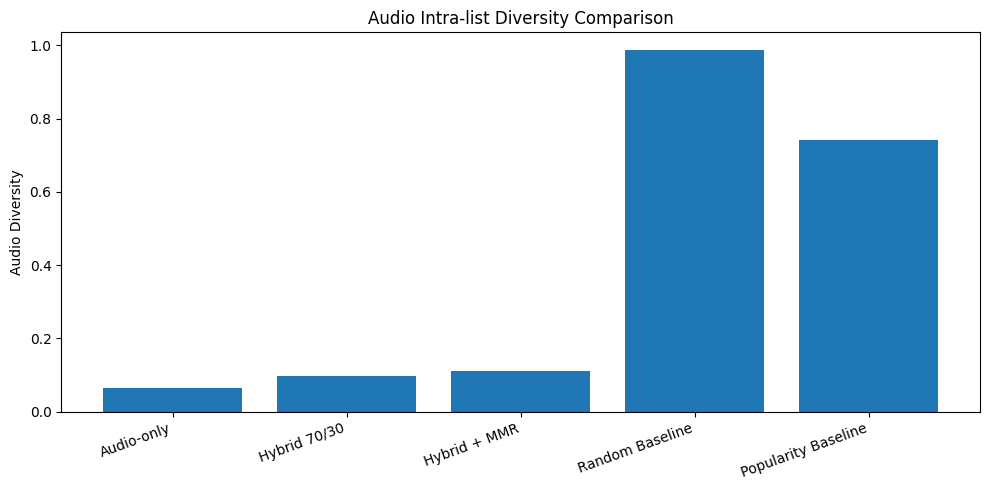

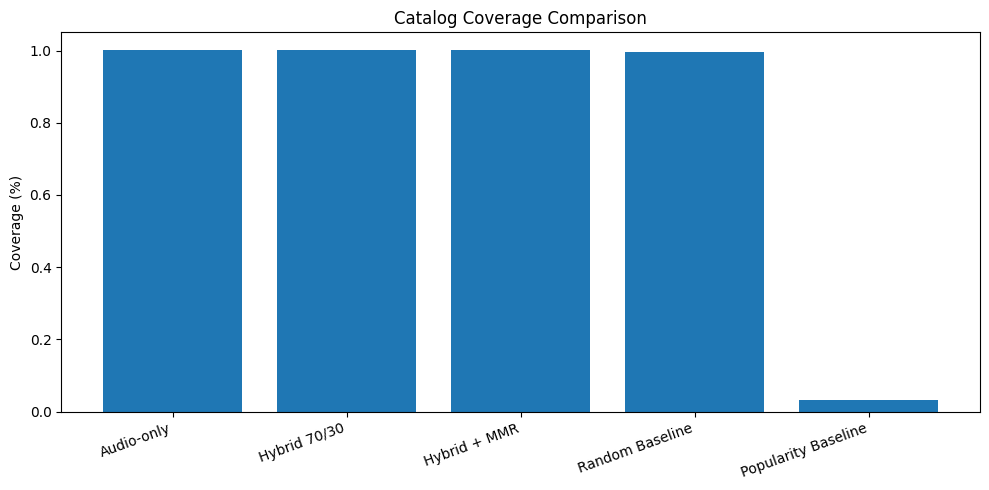

In [27]:
plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["audio_diversity"])
plt.title("Audio Intra-list Diversity Comparison")
plt.ylabel("Audio Diversity")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["coverage_pct"])
plt.title("Catalog Coverage Comparison")
plt.ylabel("Coverage (%)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


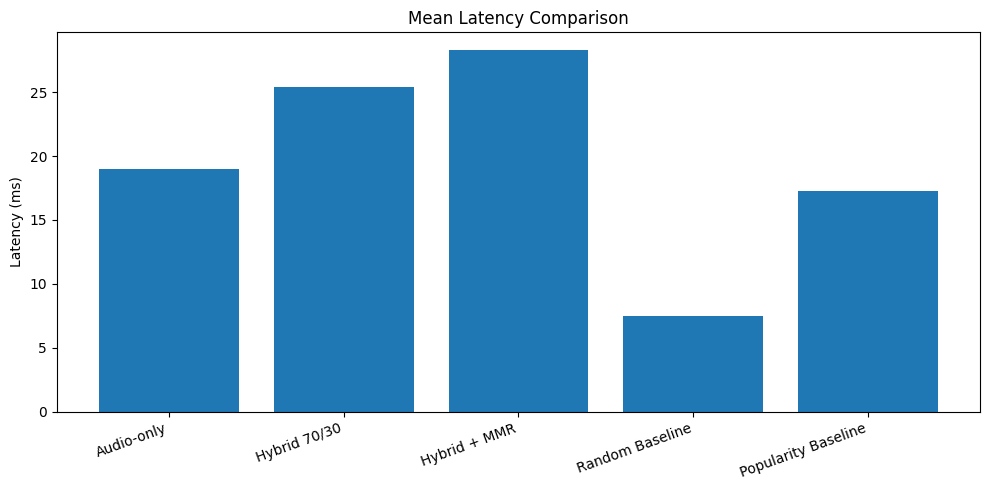

In [28]:
plt.figure(figsize=(10, 5))
plt.bar(summary_df["model"], summary_df["mean_latency_ms"])
plt.title("Mean Latency Comparison")
plt.ylabel("Latency (ms)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


In [29]:
print("=== EVALUATION VALIDATION ===")

expected_models = {
    "Audio-only", "Hybrid 70/30", "Hybrid + MMR",
    "Random Baseline", "Popularity Baseline"
}
required_metrics = [
    "model", "mean_audio_cosine", "mean_acoustic_distance",
    "audio_diversity", "coverage_pct", "mean_latency_ms"
]
missing = [column for column in required_metrics if column not in summary_df.columns]

assert not missing, f"Missing evaluation columns: {missing}"
assert len(summary_df) == 5
assert set(summary_df["model"]) == expected_models
assert len(details_df) > 0
assert metrics["catalog_size"] > 0
assert metrics["evaluation_config"]["n_queries"] == evaluation.N_QUERIES
assert summary_df[required_metrics[1:]].notna().all().all()

expected_recommendations = (
    len(expected_models)
    * metrics["evaluation_config"]["n_queries"]
    * metrics["evaluation_config"]["top_n"]
)
assert len(details_df) == expected_recommendations, (
    f"Expected {expected_recommendations} recommendation rows, got {len(details_df)}"
)

print("Catalog size:", metrics["catalog_size"])
print("Number of evaluated methods:", len(summary_df))
print("Number of queries:", metrics["evaluation_config"]["n_queries"])
print("Number of recommendations:", len(details_df))

for path in [
    metrics_path, summary_path, details_path, dashboard_path
]:
    assert path.exists()
    assert path.stat().st_mtime >= EVALUATION_STARTED_AT - 1
    print(path.name, "-", round(path.stat().st_size / 1024, 2), "KB")

print("CURRENT EVALUATION VALIDATION: PASS")


=== EVALUATION VALIDATION ===
Catalog size: 29985
Number of evaluated methods: 5
Number of queries: 30
Number of recommendations: 1500
metrics.json - 7.27 KB
evaluation_summary.csv - 1.96 KB
evaluation_details.csv - 393.11 KB
evaluation_dashboard.png - 465.48 KB
CURRENT EVALUATION VALIDATION: PASS


In [30]:
evaluate_path = PROJECT_ROOT / "src" / "evaluate.py"
evaluate_source = evaluate_path.read_text(encoding="utf-8")

assert "CANDIDATE_POOL = 50" not in evaluate_source
assert "candidate_pool=CANDIDATE_POOL" not in evaluate_source
assert "'candidate_pool': CANDIDATE_POOL" not in evaluate_source
assert "candidate_pool_policy" in evaluate_source

print("PASS: evaluate.py does not hardcode candidate_pool=50.")


PASS: evaluate.py does not hardcode candidate_pool=50.


In [31]:
from src.recommender import EmbeatRecommender

signature = inspect.signature(EmbeatRecommender.recommend_hybrid_mmr)
assert "candidate_pool" in signature.parameters
assert signature.parameters["candidate_pool"].default is None

print("MMR signature:", signature)
print("PASS: candidate_pool defaults to None; recommender selects a dynamic pool.")


MMR signature: (self, track_id, top_n=10, alpha=0.7, mmr_lambda=0.7, candidate_pool=None, exclude_same_artist=True, *, top_k=None, as_dict=False)
PASS: candidate_pool defaults to None; recommender selects a dynamic pool.


In [32]:
# Kiểm tra chính sách mặc định top_k * 3 khi không truyền candidate_pool.
for top_k in [10, 50, 100]:
    candidate_pool = top_k * 3
    assert candidate_pool >= top_k
    print(f"top_k={top_k} -> default candidate_pool={candidate_pool}")

print("PASS: Dynamic candidate-pool policy.")


top_k=10 -> default candidate_pool=30
top_k=50 -> default candidate_pool=150
top_k=100 -> default candidate_pool=300
PASS: Dynamic candidate-pool policy.
